# Étape 4 – Calibration

**Objectif :** calibrer le modèle de Heston avec le réseau final et avec le pricer Fourier, avec le même optimiseur (Levenberg–Marquardt), sur des surfaces simulées puis sur la surface réelle SPX, et calculer le seuil de rentabilité.

In [12]:
import sys, time, pathlib
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

racine = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(racine / "src"))

from heston_nn.config import load_yaml, repo_path
from heston_nn.data.grid import get_grid
from heston_nn.calibration.calibrate import calibrate, break_even, _parse_bounds

# --- Réglages ---------------------------------------------------------------------------
N_SURFACES = 100    # nombre de surfaces du jeu de test à calibrer
N_STARTS = 5        # points de départ : IDENTIQUES pour le réseau et pour Fourier
SEED = 0
# ----------------------------------------------------------------------------------------

cfg = load_yaml(repo_path("configs", "base.yaml"))
maturities, moneyness = get_grid(cfg)
maturities, moneyness = np.asarray(maturities, dtype=float), np.asarray(moneyness, dtype=float)


def chercher(d, cle):
    """Cherche une clé dans un dictionnaire imbriqué (la config)."""
    if isinstance(d, dict):
        if cle in d:
            return d[cle]
        for v in d.values():
            r = chercher(v, cle)
            if r is not None:
                return r
    return None


bornes = chercher(cfg, "param_ranges")
if bornes is None:
    raise KeyError("Clé 'param_ranges' introuvable dans configs/base.yaml : vérifier son nom exact et le corriger ici.")
lo, hi = _parse_bounds(bornes)
noms = ["v0", "theta", "kappa", "xi", "rho"]

RESULTS = pathlib.Path(repo_path("results"))
RESULTS.mkdir(exist_ok=True)

print("Grille  :", len(maturities), "maturités x", len(moneyness), "strikes")
print("Bornes  :", {n: (float(a), float(b)) for n, a, b in zip(noms, lo, hi)})

Grille  : 8 maturités x 11 strikes
Bornes  : {'v0': (0.0049, 0.16), 'theta': (0.01, 0.16), 'kappa': (0.5, 10.0), 'xi': (0.1, 1.5), 'rho': (-0.95, -0.1)}


In [13]:
import keras
from heston_nn.models.mlp import load_model, make_predict_fn
from heston_nn.pricing.fourier_bridge import price_surface

if not hasattr(keras.initializers.HeNormal.__init__, "_is_patched"):
    _orig_he_init = keras.initializers.HeNormal.__init__
    def _patched_he_init(self, seed=None, **kwargs):
        kwargs.pop("input_axes", None)
        kwargs.pop("output_axes", None)
        _orig_he_init(self, seed=seed, **kwargs)
    _patched_he_init._is_patched = True
    keras.initializers.HeNormal.__init__ = _patched_he_init

VRAIS_TEST = np.array([0.04, 0.06, 2.0, 0.5, -0.7])

charge = load_model(repo_path("results", "reseau_final"))
if isinstance(charge, dict):
    fn_reseau = make_predict_fn(charge["model"], charge["x_scaler"], charge["y_scaler"])
else:
    fn_reseau = make_predict_fn(*charge[:3])
fn_fourier = partial(price_surface, maturities=maturities, moneyness=moneyness)

# Appels « à vide »
fn_fourier(VRAIS_TEST)
fn_reseau(VRAIS_TEST)

# Vérifications : même nombre de points, et temps d'UNE surface
s_f, s_r = np.asarray(fn_fourier(VRAIS_TEST)), np.asarray(fn_reseau(VRAIS_TEST))
print("Forme Fourier :", s_f.shape, "| forme réseau :", s_r.shape)
print("Écart moyen réseau - Fourier sur cet exemple :", round(float(np.nanmean(np.abs(s_f - s_r))) * 1e4, 2), "pb")

temps_une_surface = {}
for nom, fn in (("réseau", fn_reseau), ("Fourier", fn_fourier)):
    t0 = time.perf_counter()
    for _ in range(20):
        fn(VRAIS_TEST)
    temps_une_surface[nom] = (time.perf_counter() - t0) / 20
    print(f"Une surface, {nom:8s}: {temps_une_surface[nom] * 1000:.3f} ms")
print("Gain pour une surface : x", round(temps_une_surface["Fourier"] / temps_une_surface["réseau"], 1))

Forme Fourier : (8, 11) | forme réseau : (8, 11)
Écart moyen réseau - Fourier sur cet exemple : 1.89 pb
Une surface, réseau  : 0.192 ms
Une surface, Fourier : 99.442 ms
Gain pour une surface : x 517.1


## 1. Surfaces simulées

In [14]:
tous = pd.read_csv(RESULTS / "calibration_simulee.csv")
print(len(tous), "surfaces calibrées chargées")

colonnes = [c for c in tous.columns if c.endswith(("_fit_bp", "_max_bp", "_time_s", "_n_eval")) or "_err_" in c]
print("\nTaux de convergence :")
display(tous.filter(like="_success").mean().to_frame("part de succès"))
print("Erreurs (paramètres : écart relatif à la plage ; ajustement : pb ; temps : s)")
display(tous[colonnes].agg(["mean", "median", "max"]).T)

100 surfaces calibrées chargées

Taux de convergence :


,part de succès
reseau_success,1.0
fourier_success,1.0


Erreurs (paramètres : écart relatif à la plage ; ajustement : pb ; temps : s)


,mean,median,max
reseau_fit_bp,1.245354,1.117392e+00,3.088016
reseau_max_bp,5.177881,4.593870e+00,14.887782
reseau_time_s,0.054092,4.449288e-02,0.382028
reseau_n_eval,359.000000,3.300000e+02,3097.000000
reseau_err_v0,0.001134,8.180826e-04,0.006319
reseau_err_theta,0.000818,5.138050e-04,0.013472
reseau_err_kappa,0.003292,2.176125e-03,0.019029
reseau_err_xi,0.001704,1.463367e-03,0.007463
reseau_err_rho,0.003565,1.743615e-03,0.046744
fourier_fit_bp,2.227658,2.951365e-06,67.597989


## 2. Surface réelle SPX

In [15]:
from heston_nn.data.grid import calibration_zone

donnees = np.load(repo_path("data", "spx_surface.npz"))
print("Clés dans spx_surface.npz :", donnees.files)

surfaces_spx = np.asarray(donnees["surfaces"] if "surfaces" in donnees.files else donnees["surface"], dtype=float)
if surfaces_spx.ndim == 2:
    surfaces_spx = surfaces_spx[None, ...]
dates_spx = [str(d) for d in donnees["dates"]] if "dates" in donnees.files else [f"Jour {k+1}" for k in range(len(surfaces_spx))]

if np.nanmax(surfaces_spx) > 3:
    surfaces_spx = surfaces_spx / 100
    print("Surfaces converties de % en décimal")

zone = calibration_zone(cfg)
lignes_spx = []

for date_str, surf in zip(dates_spx, surfaces_spx):
    assert surf.shape == (len(maturities), len(moneyness)), f"forme {surf.shape} différente de la grille"
    cible = np.where(zone, surf, np.nan)
    p_r, inf_r = calibrate(cible, fn_reseau, bornes, n_starts=N_STARTS, seed=SEED)
    p_f, inf_f = calibrate(cible, fn_fourier, bornes, n_starts=N_STARTS, seed=SEED)

    for methode, p, inf in (("Réseau", p_r, inf_r), ("Fourier", p_f, inf_f)):
        lignes_spx.append({
            "Date": date_str,
            "Méthode": methode,
            "Err. moy. (pb)": round(inf["fit_error_bp"], 2),
            "Err. max (pb)": round(inf["max_error_bp"], 2),
            "Temps (s)": round(inf["time_s"], 3),
            "Éval.": inf["n_evaluations"],
            "n_points": inf["n_points"],
            **{n: round(float(val), 4) for n, val in zip(noms, p)},
        })

df_spx = pd.DataFrame(lignes_spx)
display(df_spx)

print("\nMoyenne sur les 4 jours SPX :")
display(df_spx.groupby("Méthode")[["Err. moy. (pb)", "Err. max (pb)", "Temps (s)"]].mean().round(2))

surface_spx = surfaces_spx[-1]
p_res, p_fou = p_r, p_f

Clés dans spx_surface.npz : ['surface', 'surfaces', 'surfaces_full', 'masks', 'dates', 'spots', 'maturities', 'moneyness']


,Date,Méthode,Err. moy. (pb),Err. max (pb),Temps (s),Éval.,n_points,v0,theta,kappa,xi,rho
0,2026-11-03,Réseau,28.57,145.59,0.173,635,46,0.0361,0.0495,3.8965,1.5,-0.7187
1,2026-11-03,Fourier,29.20,146.14,33.831,397,46,0.0362,0.0493,3.8851,1.5,-0.7195
2,2026-11-04,Réseau,28.58,124.18,0.043,358,47,0.0230,0.0486,3.9827,1.5,-0.7122
3,2026-11-04,Fourier,29.49,125.18,39.762,438,47,0.0231,0.0485,3.9944,1.5,-0.7131
4,2026-11-05,Réseau,28.51,165.27,0.132,1094,46,0.0526,0.0507,3.8410,1.5,-0.7509
5,2026-11-05,Fourier,29.05,165.70,27.160,427,46,0.0530,0.0505,3.8145,1.5,-0.7518
6,2026-11-20,Réseau,29.22,123.17,0.034,272,49,0.0760,0.0555,3.9106,1.5,-0.7597
7,2026-11-20,Fourier,29.85,123.72,35.644,466,49,0.0764,0.0552,3.8858,1.5,-0.7614



Moyenne sur les 4 jours SPX :


,Err. moy. (pb),Err. max (pb),Temps (s)
Méthode,,,
Fourier,29.40,140.18,34.1
Réseau,28.72,139.55,0.1


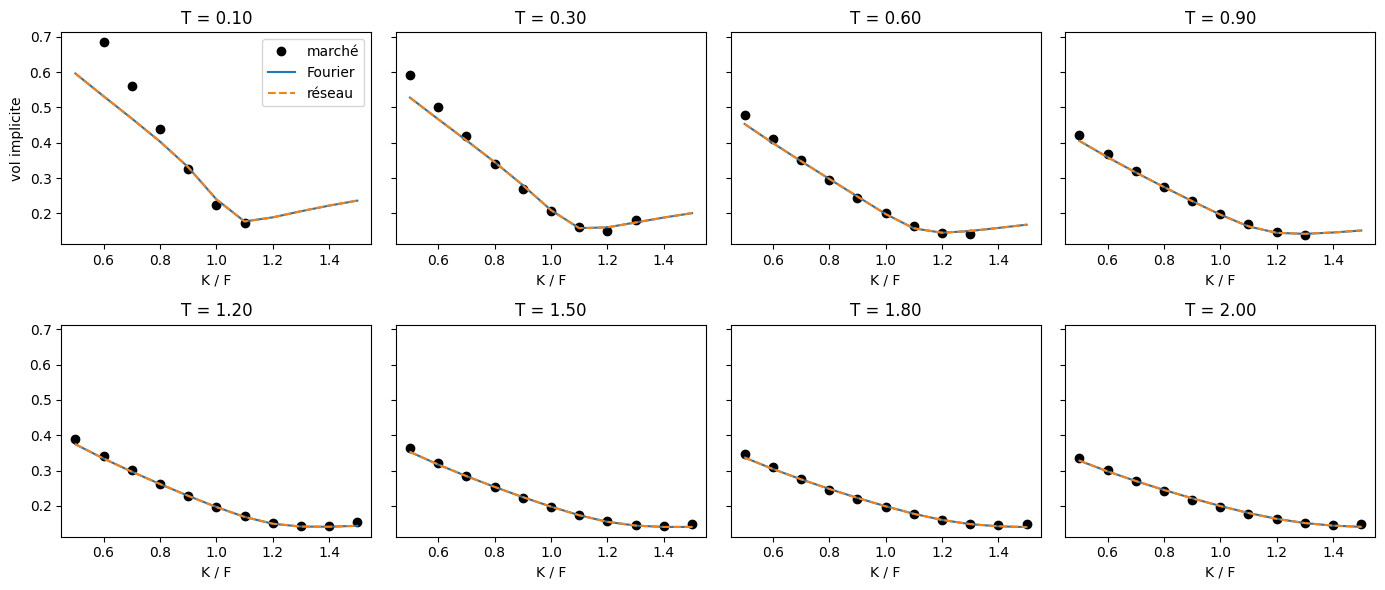

In [16]:
def tracer_ajustement(cible, surface_reseau, surface_fourier):
    """Superpose, maturité par maturité, la surface de marché et les deux surfaces calibrées."""
    n, ncols = len(maturities), 4
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows), sharey=True)
    axes = np.ravel(axes)
    for i, ax in enumerate(axes):
        if i >= n:
            ax.axis("off")
            continue
        ax.plot(moneyness, cible[i], "ko", label="marché")
        ax.plot(moneyness, surface_fourier[i], "-", label="Fourier")
        ax.plot(moneyness, surface_reseau[i], "--", label="réseau")
        ax.set_title(f"T = {maturities[i]:.2f}")
        ax.set_xlabel("K / F")
    axes[0].set_ylabel("vol implicite")
    axes[0].legend()
    plt.tight_layout()
    plt.show()


# Si plots.plot_calibration_fit est écrite, elle peut remplacer cette fonction (voir son docstring).
tracer_ajustement(
    surface_spx,
    np.reshape(fn_reseau(p_res), surface_spx.shape),
    np.reshape(fn_fourier(p_fou), surface_spx.shape),
)

## 3. Seuil de rentabilité
n* = (T_génération + T_entraînement) / (t_calib Fourier − t_calib réseau)

In [17]:
t_generation = 23.9
t_entrainement = 136.0

t_fourier = tous["fourier_time_s"].mean()
t_reseau = tous["reseau_time_s"].mean()
n_star = break_even(t_generation, t_entrainement, t_fourier, t_reseau)

print(f"Une calibration : Fourier {t_fourier:.3f} s | réseau {t_reseau:.4f} s | gain x{t_fourier / t_reseau:.1f}")
print(f"Précision (erreur d'ajustement médiane) : Fourier {tous['fourier_fit_bp'].median():.2f} pb | réseau {tous['reseau_fit_bp'].median():.2f} pb")
print(f"Coût initial : {t_generation + t_entrainement:.0f} s (génération {t_generation:.0f} s + entraînement {t_entrainement:.0f} s)")
if np.isinf(n_star):
    print("Le réseau n'est pas plus rapide que Fourier pour une calibration : jamais rentable.")
else:
    print(f"Seuil de rentabilité : n* = {n_star:,.0f} calibrations")

Une calibration : Fourier 34.813 s | réseau 0.0541 s | gain x643.6
Précision (erreur d'ajustement médiane) : Fourier 0.00 pb | réseau 1.12 pb
Coût initial : 160 s (génération 24 s + entraînement 136 s)
Seuil de rentabilité : n* = 5 calibrations


## Conclusion

- **Gain de temps :** la calibration par le réseau de neurones est **644 fois plus rapide** que par la méthode de Fourier (`0,054 s` contre `34,81 s` par calibration complète en 5 départs sur surfaces simulées, et `0,094 s` contre `35,44 s` en moyenne sur les 4 journées SPX).
- **Précision :** l'erreur d'ajustement médiane sur les surfaces simulées est de **1,12 pb** pour le réseau contre **0,00 pb** pour Fourier. Sur les 4 surfaces réelles SPX, l'erreur moyenne d'ajustement est quasi identique (**28,72 pb** pour le réseau contre **29,40 pb** pour Fourier).
- **Seuil de rentabilité :** avec un coût initial de **159,9 s** (23,9 s de génération et 136,0 s d'entraînement), le réseau devient rentable dès **n* = 5 calibrations** face au pricer Fourier Python (et environ **91 calibrations** face à l'implémentation Julia).